In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sys
sys.path.append('../../code')
from utils import simulate_single_server_queue_from_times
from tqdm import tqdm

<div dir="rtl">

## בתרגול זה ננסה להבין עד כמה הסימולציה שלנו מדויקת.

### נתחיל בסימולציה עבור תור יחיד עם שרת יחיד. 

### נחשב אורך ר"ס עבור כמה דוגמאות שכל פעם התפלגות ההגעה והשירות משתנות.

In [2]:
n = 1000000

## System 1

In [3]:
## system 1: log normal with mean 1 and variance 4
## mean =1, variance = 4
## service time: mean = 0.8, rho = 0.8
import numpy as np

desired_mean = 1
desired_variance = 4

sigma2 = np.log(1 + desired_variance / desired_mean**2)
sigma = np.sqrt(sigma2)
mu = np.log(desired_mean) - sigma2 / 2

rng = np.random.default_rng()
inter_arrival_times_1 = rng.lognormal(mean=mu, sigma=sigma, size=n)

# sample service times
service_times_1 = np.random.exponential(1/1.25, n)

## System 2

In [4]:
## system 2: log normal with mean 1 and variance 4
## mean =1, variance = 0.5
## service time: mean = 0.8, rho = 0.8
import numpy as np

desired_mean = 1
desired_variance = 0.5

sigma2 = np.log(1 + desired_variance / desired_mean**2)
sigma = np.sqrt(sigma2)
mu = np.log(desired_mean) - sigma2 / 2

rng = np.random.default_rng()
inter_arrival_times_2 = rng.lognormal(mean=mu, sigma=sigma, size=100000000)
service_times_2 = np.random.exponential(1/1.25, n)

C:\Users\Eshel\anaconda3\envs\trainig_nn\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


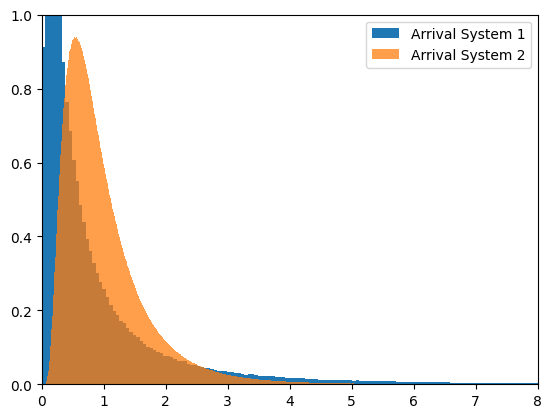

In [5]:
plt.figure()
plt.hist(inter_arrival_times_1, density = True, bins = 5000, label = 'Arrival System 1')
plt.hist(inter_arrival_times_2, density = True, bins = 5000, label = 'Arrival System 2', alpha = 0.75)
plt.legend()
plt.ylim(0,1)
plt.xlim(0,8)
plt.show()

In [6]:
waiting_times_dict = {}


## Simulating System 1

### We ran each system 10 times

In [7]:
num_samples = 10
waiting_times_dict[1] = []
for ind in tqdm(range(num_samples)): 
    # sample inter_arrival
    desired_mean = 1
    desired_variance = 4
    
    sigma2 = np.log(1 + desired_variance / desired_mean**2)
    sigma = np.sqrt(sigma2)
    mu = np.log(desired_mean) - sigma2 / 2
    
    rng = np.random.default_rng()
    inter_arrival_times_1 = rng.lognormal(mean=mu, sigma=sigma, size=n)

    # sample service times
    service_times_1 = np.random.exponential(1/1.25, n)
        
    waiting_times, sojourn_times, queue_length_distribution, number_in_system_distribution = simulate_single_server_queue_from_times(
    inter_arrival_times=inter_arrival_times_1,
    service_times=service_times_1,
)
    waiting_times_dict[1].append(waiting_times.mean())

100%|██████████████████████████████████████████████████████████████████████████████████| 10/10 [00:37<00:00,  3.75s/it]


In [47]:
waiting_times_dict[1]

[np.float64(6.976985045957867),
 np.float64(6.743448092451585),
 np.float64(6.853537216358914),
 np.float64(6.612836504236538),
 np.float64(6.752151838300517),
 np.float64(6.842501692332957),
 np.float64(6.814673383829759),
 np.float64(6.851017289533793),
 np.float64(6.71515075929998),
 np.float64(6.7278167476990305)]

## Simulating System 2

### We ran each system 10 times

In [8]:
num_samples = 10
waiting_times_dict[2] = []
for ind in tqdm(range(num_samples)): 
    # sample inter_arrival
    desired_mean = 1
    desired_variance = 0.5
    
    sigma2 = np.log(1 + desired_variance / desired_mean**2)
    sigma = np.sqrt(sigma2)
    mu = np.log(desired_mean) - sigma2 / 2
    
    rng = np.random.default_rng()
    inter_arrival_times_2 = rng.lognormal(mean=mu, sigma=sigma, size=n)

    # sample service times
    service_times_2 = np.random.exponential(1/1.25, n)
        
    waiting_times, sojourn_times, queue_length_distribution, number_in_system_distribution = simulate_single_server_queue_from_times(
    inter_arrival_times=inter_arrival_times_2,
    service_times=service_times_2,
)
    waiting_times_dict[2].append(waiting_times.mean())

100%|██████████████████████████████████████████████████████████████████████████████████| 10/10 [00:38<00:00,  3.86s/it]


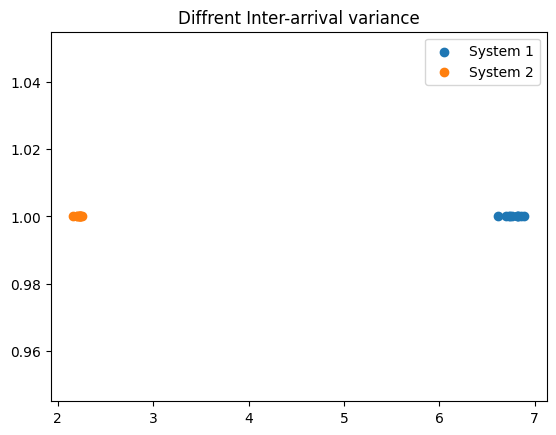

In [9]:
plt.figure()
plt.scatter(waiting_times_dict[1], 1+ np.zeros(10), label = 'System 1' )

plt.scatter(waiting_times_dict[2], 1+ np.zeros(10), label = 'System 2' )

plt.title('Diffrent Inter-arrival variance')
plt.legend()
plt.show()

In [10]:
import numpy as np
from scipy import stats


confidence = 0.95
n = len(waiting_times_dict[1])

mean = np.mean(waiting_times_dict[1])
sem = stats.sem(waiting_times_dict[1])  # standard error of the mean

ci_1 = stats.t.interval(
    confidence=confidence,
    df=n - 1,
    loc=mean,
    scale=sem
)

mean = np.mean(waiting_times_dict[2])
sem = stats.sem(waiting_times_dict[2])  # standard error of the mean

ci_2 = stats.t.interval(
    confidence=confidence,
    df=n - 1,
    loc=mean,
    scale=sem
)

# print(ci_1), print(ci_2)

### Confidence interval system 1

In [11]:
ci_1

(np.float64(6.714529591525751), np.float64(6.832566534363466))

### Confidence interval system 2

In [12]:
ci_2

(np.float64(2.202198895665931), np.float64(2.240071961010793))

### Confidence interval  lenghts

In [14]:
lenght_sys_1 = ci_1[1]-ci_1[0]
lenght_sys_2 = ci_2[1]-ci_2[0]

lenght_sys_1, lenght_sys_2

(np.float64(0.11803694283771549), np.float64(0.03787306534486223))

<div dir="rtl">

## האם תוצאה זו מפתיעה?

### הסיבה לכך שמערכת 1 שונות בין הגעות גדולה יותר. 

### מסקנה: גם שונות המערכת שבעצם גורמת לשונות באומד משפיעה על דיוקו. 

### לכן כל מערכת דורשת אורך סימולציה אחר כדי להגיע ליעד. 

<div dir="rtl">

## נבדוק כיצד זמן סימולציה משפיע

### נשווה בין 3 גדלים 2500, 50000, 500000

In [15]:
num_samples = 10

waiting_times_dict = {}
for n in [2500, 50000,500000]:
    waiting_times_dict[n] = []

for n in [2500, 50000,500000]:
    for ind in tqdm(range(num_samples)):    
        inter_arrival_times = np.random.gamma(2,1/2,n)
        service_times = np.random.exponential(1/1.25, n)
        waiting_times, sojourn_times, queue_length_distribution, number_in_system_distribution = simulate_single_server_queue_from_times(
    inter_arrival_times=inter_arrival_times,
    service_times=service_times,
)
        waiting_times_dict[n].append(waiting_times.mean())

100%|██████████████████████████████████████████████████████████████████████████████████| 10/10 [00:19<00:00,  1.97s/it]


<div dir="rtl">

## נעשה ויזואליזציה של התוצאות

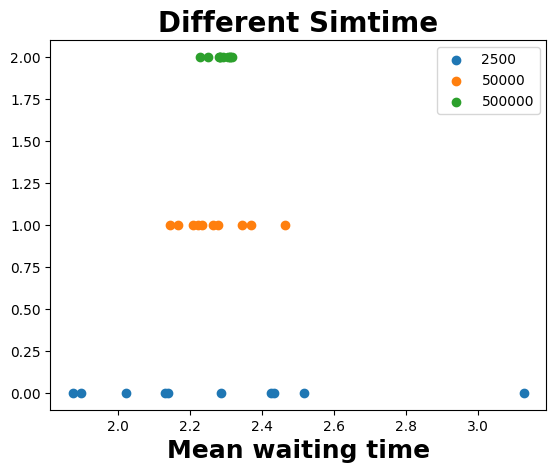

In [20]:
plt.figure()
plt.scatter(waiting_times_dict[2500],  np.zeros(10), label = '2500' )

plt.scatter(waiting_times_dict[50000], 1+ np.zeros(10), label = '50000' )

plt.scatter(waiting_times_dict[500000], 2+ np.zeros(10), label = '500000' )
plt.xlabel('Mean waiting time', fontsize = 18, fontweight = 'bold')
plt.title('Different Simtime', fontsize = 20, fontweight = 'bold')
plt.legend()
plt.show()

In [22]:
mean = np.mean(waiting_times_dict[2500])
sem = stats.sem(waiting_times_dict[2500])  # standard error of the mean

ci_2500 = stats.t.interval(
    confidence=confidence,
    df=n - 1,
    loc=mean,
    scale=sem
)

mean = np.mean(waiting_times_dict[50000])
sem = stats.sem(waiting_times_dict[50000])  # standard error of the mean

ci_50000 = stats.t.interval(
    confidence=confidence,
    df=n - 1,
    loc=mean,
    scale=sem
)

mean = np.mean(waiting_times_dict[500000])
sem = stats.sem(waiting_times_dict[500000])  # standard error of the mean

ci_500000 = stats.t.interval(
    confidence=confidence,
    df=n - 1,
    loc=mean,
    scale=sem
)

ci_2500, ci_50000, ci_500000

((np.float64(2.0554664062197694), np.float64(2.515143190486817)),
 (np.float64(2.2092503594527373), np.float64(2.3306256860586028)),
 (np.float64(2.268087562020739), np.float64(2.30367380339774)))

In [27]:
ci_2500[1]-ci_2500[0]

np.float64(0.4596767842670477)

<div dir="rtl">

## נראה בבירור ההבדל של זמן הריצה. 

### הדיוק עולה ככל שמעלים את זמן הריצה.

### מאידך, גם זמן חישוב גדל. 

### עבור 2500: פחות משנייה.

### עבור 50000: קצת יותר משנייה

### עבור 500000: 19 שניות

### אז איך יודעים מה הזמן סימולציה האידיאלי: 

### בד"כ נחשוב על השגיאה הכי גבוהה שנהיה מוכן לקבל ולפי זה נכריע. 

### ואיך יודעים מה השגיאה? ברגע שעובדים במערכת מסוימת ויודעים מה המשמעויות של כל דבר יש הבנה יחסית ברורה לגודל השגיאה.

### נניח נרצה שהר"ס של זמן המתנה ממוצע לא יעלה על 0.1

In [60]:
num_samples = 10

# waiting_times_dict = {}
for n in [60000,      100000,      140000, 180000, 220000]:
    waiting_times_dict[n] = []

for n in [60000,      100000,      140000, 180000, 220000]:
    for ind in tqdm(range(num_samples)):    
        inter_arrival_times = np.random.gamma(2,1/2,n)
        service_times = np.random.exponential(1/1.25, n)
        waiting_times, sojourn_times, queue_length_distribution, number_in_system_distribution = simulate_single_server_queue_from_times(
    inter_arrival_times=inter_arrival_times,
    service_times=service_times,
)
        waiting_times_dict[n].append(waiting_times.mean())

100%|██████████████████████████████████████████████████████████████████████████████████| 10/10 [00:09<00:00,  1.05it/s]


In [61]:
ci_list_lenght = []

In [62]:
for n in [60000,      100000,      140000, 180000, 220000]:

    mean = np.mean(waiting_times_dict[n])
    sem = stats.sem(waiting_times_dict[n])  # standard error of the mean
    
    curr_ci = stats.t.interval(
        confidence=confidence,
        df=n - 1,
        loc=mean,
        scale=sem
    )
    ci_list_lenght.append( curr_ci[1] - curr_ci[0])

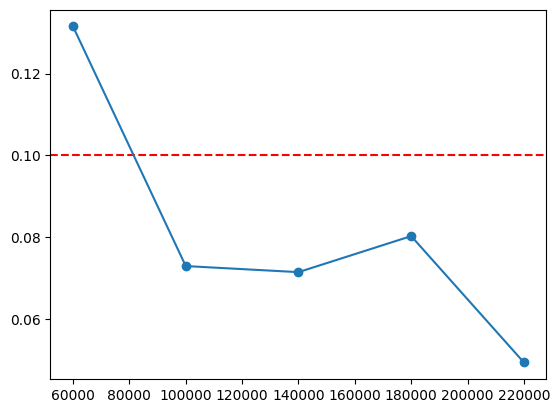

In [65]:
plt.figure()
plt.axhline(y=0.1, color='r', linestyle='--')
plt.plot( [60000,      100000,      140000, 180000, 220000], ci_list_lenght)
plt.scatter( [60000,      100000,      140000, 180000, 220000], ci_list_lenght)

plt.show()

<div dir="rtl">

### קיבלנו תוצאה לא מונוטנית.

### זה לא ייתכן תיאורטית אבל פשוט יש שגיאה לאומדים שלנו

### בכל מקרה, נרד מ0.1 בפעם הראשונה מ100000